# Statistiques sur le stock de contentieux en cours

Ce notebook décrit le **stock** à une date donnée : les personnes qui ont actuellement au moins un document en retard de plus de 28 jours (seuil d'entrée dans le circuit : appel téléphonique, rapport Koha 207). Il est distinct de `adm_contentieux_statistiques.ipynb`, qui mesure combien de personnes passent en contentieux au cours d'une année.

Circuit de gestion (bloc « adresse alternative » `B_` de la fiche adhérent) :

| Champ | Usage |
|---|---|
| `B_address` | date de l'appel téléphonique |
| `B_address2` | résultat de l'appel (usager joint / message vocal / téléphone inconnu) |
| `B_city` | date de demande de création du tiers |
| `B_zipcode` | numéro de tiers GF |
| `B_state` | numéro du titre de recette ; `0` = pas de titre, montant < 15 € |
| `B_country` | date du titre de recette |
| `contactnote` | documents facturés (code-barres et prix) |

Règles de méthode :
- les dates du bloc `B_` sont saisies en deux formats (AAAA-MM-JJ et JJ/MM/AAAA) : les deux sont lus ;
- une information du bloc `B_` n'est rattachée au dossier actuel que si sa date est postérieure à la plus ancienne échéance en retard : sinon, elle concerne un dossier antérieur (le bloc n'a qu'un emplacement par étape) ;
- quand une donnée est incertaine (prix manquant, date illisible), on donne un **plancher et un plafond** ;
- aucune donnée nominative n'est affichée.

In [1]:
import re

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns
sns.set_style("darkgrid")

from scipy import stats

from kiblib.utils.db import DbConn

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)

In [2]:
db_conn = DbConn().create_engine()

SEUIL_STOCK = 28          # entrée dans le circuit (appel téléphonique)
SEUIL_TITRE_EUR = 15      # seuil de mise en recouvrement
COLLECTIVITES = ['ECOL', 'CLAS', 'COLS', 'COLD', 'COLI']
TRANCHES = [SEUIL_STOCK, 42, 90, 180, 365, 730, 100000]
LIB_TRANCHES = ['29-42 j', '43-90 j', '91-180 j', '181-365 j', '1-2 ans', '> 2 ans']

# Préparation des données

## Date de fraîcheur

In [3]:
fraicheur = pd.read_sql("""
    SELECT GREATEST(
        (SELECT MAX(issuedate) FROM koha_prod.issues),
        (SELECT MAX(returndate) FROM koha_prod.old_issues)
    ) AS fraicheur""", db_conn).iloc[0, 0]
fraicheur = pd.Timestamp(fraicheur).normalize()
fraicheur

Timestamp('2026-10-14 00:00:00')

## Prêts en cours et exemplaires

In [4]:
prets = pd.read_sql("""
SELECT i.borrowernumber, i.itemnumber, i.issuedate, i.date_due, i.branchcode AS site_pret,
       it.replacementprice, it.itemlost, it.itype, it.ccode, it.homebranch, it.biblionumber
FROM koha_prod.issues i
LEFT JOIN koha_prod.items it ON it.itemnumber = i.itemnumber
""", db_conn)
prets['echeance'] = pd.to_datetime(prets['date_due'], errors='coerce').dt.normalize()
prets['retard'] = (fraicheur - prets['echeance']).dt.days
prets['prix'] = prets['replacementprice'].where(prets['replacementprice'] > 0)

# prix imputé (plafond) : médiane du type de document, calculée sur tout le catalogue
prix_type = pd.read_sql("""
SELECT itype, replacementprice FROM koha_prod.items WHERE replacementprice > 0
""", db_conn).groupby('itype')['replacementprice'].median()
prets['prix_haut'] = prets['prix'].fillna(prets['itype'].map(prix_type)).fillna(prix_type.median())
prets['prix_bas'] = prets['prix'].fillna(0)

resa = pd.read_sql("SELECT DISTINCT biblionumber FROM koha_prod.reserves", db_conn)
prets['titre_reserve'] = prets['biblionumber'].isin(resa['biblionumber'])

print(len(prets), "prêts en cours,", (prets['retard'] > SEUIL_STOCK).sum(), "en retard de plus de", SEUIL_STOCK, "jours")

41531 prêts en cours, 9319 en retard de plus de 28 jours


## Adhérents, bloc `B_`, suspensions, activité

In [5]:
adh = pd.read_sql("""
SELECT borrowernumber, categorycode, dateofbirth, branchcode, dateenrolled, dateexpiry,
       phone, mobile, email,
       B_address, B_address2, B_city, B_state, B_zipcode, B_country, contactnote
FROM koha_prod.borrowers
""", db_conn)

def renseigne(s):
    return s.notna() & (s.astype(str).str.strip() != '')

def lire_date(s):
    s = s.astype(str).str.strip()
    d = pd.to_datetime(s, format='%Y-%m-%d', errors='coerce')
    return d.fillna(pd.to_datetime(s, format='%d/%m/%Y', errors='coerce'))

for champ, nom in [('B_address', 'date_appel'), ('B_city', 'date_tiers'), ('B_country', 'date_titre')]:
    adh[nom] = lire_date(adh[champ])
    adh[nom + '_illisible'] = renseigne(adh[champ]) & adh[nom].isna()

adh['resultat_appel'] = adh['B_address2'].where(adh['B_address2'].isin(['usager joint', 'message vocal', 'téléphone inconnu']))
num_titre = adh['B_state'].astype(str).str.strip()
adh['titre'] = np.select([num_titre == '0', num_titre.str.fullmatch(r'\d{6,9}')], ['0 (< 15 €)', 'numéro'], default=None)
adh['tel'] = renseigne(adh['phone']) | renseigne(adh['mobile'])
adh['courriel'] = renseigne(adh['email'])

# montant facturé lu dans contactnote : "(7.90)" ou "- 7.90"
def montant(note):
    if not isinstance(note, str):
        return np.nan
    m = re.findall(r'(?:\(|-\s*)(\d+[.,]\d{1,2})', note)
    return sum(float(x.replace(',', '.')) for x in m) if m else np.nan
adh['montant_note'] = adh['contactnote'].map(montant)

susp = pd.read_sql("""
SELECT borrowernumber, MIN(created) AS date_suspension
FROM koha_prod.borrower_debarments WHERE type = 'OVERDUES' GROUP BY borrowernumber
""", db_conn)
adh = adh.merge(susp, on='borrowernumber', how='left')

# dernier prêt (en cours ou rendu) : sert à savoir si la personne revient emprunter.
# Koha anonymise les prêts rendus (old_issues.borrowernumber = compte anonyme) :
# l'historique par personne vient donc de statdb.stat_issues, qui garde l'emprunteur.
activite = pd.read_sql("""
SELECT borrowernumber, MAX(issuedate) AS dernier_pret FROM (
    SELECT borrowernumber, issuedate FROM koha_prod.issues
    UNION ALL
    SELECT borrowernumber, issuedate FROM statdb.stat_issues WHERE issuedate >= '2020-01-01'
) t GROUP BY borrowernumber
""", db_conn)
adh = adh.merge(activite, on='borrowernumber', how='left')
print(len(adh), "adhérents")
print("dates illisibles :", {c: int(adh[c].sum()) for c in adh.columns if c.endswith('_illisible')})

35598 adhérents
dates illisibles : {'date_appel_illisible': 29, 'date_tiers_illisible': 29, 'date_titre_illisible': 0}


## Constitution du stock (une ligne par personne)

In [6]:
r = prets[prets['retard'] > SEUIL_STOCK]
stock = r.groupby('borrowernumber').agg(
    docs=('itemnumber', 'size'),
    plus_ancienne_echeance=('echeance', 'min'),
    retard_max=('retard', 'max'),
    valeur_bas=('prix_bas', 'sum'),
    valeur_haut=('prix_haut', 'sum'),
    docs_non_restitues=('itemlost', lambda s: (s == 1).sum()),
    docs_reserves=('titre_reserve', 'sum'),
).reset_index()
stock = stock.merge(adh, on='borrowernumber', how='left')
stock['tranche'] = pd.cut(stock['retard_max'], TRANCHES, labels=LIB_TRANCHES)
stock['type'] = np.where(stock['categorycode'].isin(COLLECTIVITES), 'collectivité',
                np.where(stock['categorycode'] == 'CGEN', 'compte générique', 'particulier'))
print(len(stock), "personnes dans le stock")
stock['type'].value_counts()

2887 personnes dans le stock


particulier     2694
collectivité     193
Name: type, dtype: int64

# 1. Volume et ancienneté du stock
Valeur : plancher = prix de remplacement Koha, prix manquant compté 0 ; plafond = prix manquant remplacé par la médiane du type de document.

In [7]:
print("prêts > 28 j sans prix de remplacement :", int(r['prix'].isna().sum()), "/", len(r))

def synthese(df, groupe):
    t = df.groupby(groupe).agg(personnes=('borrowernumber', 'size'), docs=('docs', 'sum'),
                               valeur_bas=('valeur_bas', 'sum'), valeur_haut=('valeur_haut', 'sum'))
    t.loc['Total'] = t.sum()
    t['%_personnes'] = 100 * t['personnes'] / t.loc['Total', 'personnes']
    t['%_docs'] = 100 * t['docs'] / t.loc['Total', 'docs']
    return t.round(1)

synthese(stock, 'tranche')

prêts > 28 j sans prix de remplacement : 2179 / 9319


,personnes,docs,valeur_bas,valeur_haut,%_personnes,%_docs
tranche,,,,,,
29-42 j,60.0,206.0,1923.9,2703.2,2.1,2.2
43-90 j,75.0,214.0,1980.8,2811.8,2.6,2.3
91-180 j,136.0,335.0,3115.5,4418.0,4.7,3.6
181-365 j,205.0,438.0,4991.0,6705.0,7.1,4.7
1-2 ans,382.0,861.0,7756.4,10514.4,13.2,9.2
> 2 ans,2029.0,7265.0,69703.8,92840.0,70.3,78.0
Total,2887.0,9319.0,89471.3,119992.4,100.0,100.0


In [8]:
synthese(stock, 'type')

,personnes,docs,valeur_bas,valeur_haut,%_personnes,%_docs
type,,,,,,
collectivité,193.0,2381.0,20593.7,28427.7,6.7,25.5
particulier,2694.0,6938.0,68877.6,91564.6,93.3,74.5
Total,2887.0,9319.0,89471.3,119992.4,100.0,100.0


### Concentration
Part des documents et de la valeur détenus par les 10 % et 20 % de personnes qui ont le plus de documents.

In [9]:
s = stock.sort_values('docs', ascending=False)
for p in [0.01, 0.10, 0.20]:
    n = int(round(p * len(s)))
    print(f"{int(p*100):>3} % des personnes ({n}) : {100*s['docs'].head(n).sum()/s['docs'].sum():.1f} % des documents, "
          f"{100*s['valeur_bas'].head(n).sum()/s['valeur_bas'].sum():.1f} % de la valeur (plancher)")
stock['docs'].describe(percentiles=[.5, .75, .9, .99]).round(1)

  1 % des personnes (29) : 20.0 % des documents, 18.0 % de la valeur (plancher)
 10 % des personnes (289) : 45.7 % des documents, 45.7 % de la valeur (plancher)
 20 % des personnes (577) : 61.1 % des documents, 61.0 % de la valeur (plancher)


count    2887.0
mean        3.2
std        11.5
min         1.0
50%         1.0
75%         3.0
90%         6.0
99%        20.0
max       540.0
Name: docs, dtype: float64

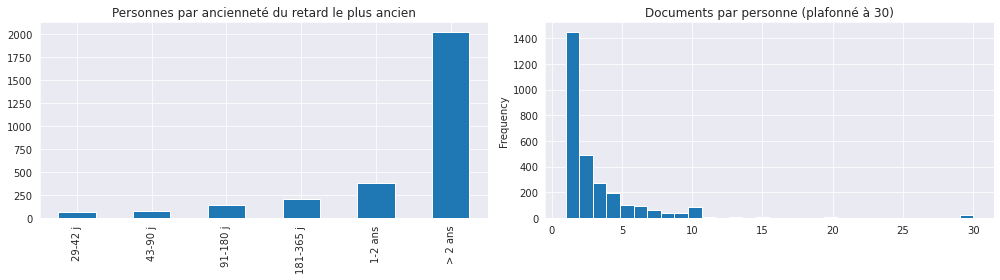

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
stock['tranche'].value_counts().reindex(LIB_TRANCHES).plot.bar(ax=axes[0], title='Personnes par ancienneté du retard le plus ancien')
stock['docs'].clip(upper=30).plot.hist(bins=30, ax=axes[1], title='Documents par personne (plafonné à 30)')
plt.tight_layout()
plt.show()

# 2. Où en est chaque dossier dans le circuit ?

Une étape n'est retenue que si sa date est postérieure à la plus ancienne échéance en retard. Une information plus ancienne concerne un dossier antérieur : la personne est alors considérée comme non traitée pour le dossier actuel.

Étapes, de la plus avancée à la moins avancée :
1. titre émis (numéro de titre) ;
2. clos sans titre, montant < 15 € (`B_state = 0`) ;
3. titre daté sans numéro ;
4. tiers demandé, pas encore de titre ;
5. appelé (selon le résultat) ;
6. non traité, avec ou sans téléphone.

Bornes : une date illisible est comptée comme rattachée au dossier actuel pour le plancher des « non traités », et comme non rattachée pour le plafond.

In [11]:
def etape(df, illisible_rattache):
    def lie(nom):
        ok = df[nom] >= df['plus_ancienne_echeance']
        return ok | (df[nom + '_illisible'] & illisible_rattache)
    titre_lie, tiers_lie, appel_lie = lie('date_titre'), lie('date_tiers'), lie('date_appel')
    return pd.Series(np.select(
        [titre_lie & (df['titre'] == 'numéro'),
         titre_lie & (df['titre'] == '0 (< 15 €)'),
         titre_lie,
         tiers_lie,
         appel_lie & (df['resultat_appel'] == 'usager joint'),
         appel_lie & (df['resultat_appel'] == 'message vocal'),
         appel_lie & (df['resultat_appel'] == 'téléphone inconnu'),
         appel_lie,
         df['tel']],
        ['1 titre émis', '2 clos < 15 €', '3 titre daté sans numéro', '4 tiers demandé',
         '5a appelé : usager joint', '5b appelé : message vocal', '5c appelé : téléphone inconnu', '5d appelé : résultat non noté',
         '6a non traité, téléphone connu'],
        default='6b non traité, sans téléphone'), index=df.index)

stock['etape'] = etape(stock, illisible_rattache=True)
stock['etape_si_illisible_non_rattache'] = etape(stock, illisible_rattache=False)
stock['bloc_dossier_anterieur'] = (renseigne(stock['B_address']) | renseigne(stock['B_country'])) & stock['etape'].str.startswith('6')

part = stock[stock['type'] == 'particulier']
t = pd.crosstab(part['etape'], part['tranche'], margins=True, margins_name='Total')
t

tranche,29-42 j,43-90 j,91-180 j,181-365 j,1-2 ans,> 2 ans,Total
etape,,,,,,,
1 titre émis,0,0,0,0,74,988,1062
2 clos < 15 €,0,0,0,0,86,532,618
3 titre daté sans numéro,0,0,0,0,0,106,106
4 tiers demandé,0,0,0,0,9,10,19
5a appelé : usager joint,0,6,21,42,32,14,115
5b appelé : message vocal,0,29,71,115,105,6,326
5c appelé : téléphone inconnu,0,0,5,30,22,7,64
5d appelé : résultat non noté,0,0,0,0,1,0,1
"6a non traité, téléphone connu",58,34,30,12,35,163,332


In [12]:
print("Non traités (particuliers) : plancher", int(part['etape'].str.startswith('6').sum()),
      "/ plafond", int(part['etape_si_illisible_non_rattache'].str.startswith('6').sum()))
print("dont bloc B_ rempli pour un dossier antérieur :", int(part['bloc_dossier_anterieur'].sum()))
part.groupby('etape').agg(personnes=('borrowernumber', 'size'), docs=('docs', 'sum'),
                          valeur_bas=('valeur_bas', 'sum'), valeur_haut=('valeur_haut', 'sum'),
                          retard_median_j=('retard_max', 'median')).round(0)

Non traités (particuliers) : plancher 383 / plafond 383
dont bloc B_ rempli pour un dossier antérieur : 131


,personnes,docs,valeur_bas,valeur_haut,retard_median_j
etape,,,,,
1 titre émis,1062,3575,38084.0,48218.0,1616.0
2 clos < 15 €,618,775,5496.0,7916.0,1601.0
3 titre daté sans numéro,106,385,4458.0,5467.0,3108.0
4 tiers demandé,19,26,260.0,293.0,1134.0
5a appelé : usager joint,115,233,2119.0,2944.0,291.0
5b appelé : message vocal,326,713,5712.0,9333.0,278.0
5c appelé : téléphone inconnu,64,185,2728.0,3219.0,324.0
5d appelé : résultat non noté,1,1,11.0,11.0,498.0
"6a non traité, téléphone connu",332,903,8399.0,12100.0,673.0


### Suspensions automatiques
Les règles de relance Koha envoient un premier rappel à 7 jours, un deuxième à 14 jours et une facture à 42 jours. La suspension automatique (`OVERDUES`) a été désactivée : plus aucune n'est créée depuis fin mars 2026. Or le rapport 208 (titres de recettes à créer) part des suspensions : les dossiers ouverts depuis ne peuvent pas y apparaître.

In [13]:
suspensions_mois = pd.read_sql("""
SELECT YEAR(created) AS annee, MONTH(created) AS mois, COUNT(*) AS suspensions
FROM koha_prod.borrower_debarments
WHERE type = 'OVERDUES' AND created >= '2025-01-01'
GROUP BY annee, mois ORDER BY annee, mois
""", db_conn)
lettres_mois = pd.read_sql("""
SELECT YEAR(time_queued) AS annee, MONTH(time_queued) AS mois, COUNT(*) AS factures_42j
FROM koha_prod.message_queue
WHERE letter_code = 'FACTURE' AND time_queued >= '2025-01-01'
GROUP BY annee, mois ORDER BY annee, mois
""", db_conn)
lettres_mois.merge(suspensions_mois, on=['annee', 'mois'], how='left').fillna(0).astype(int).set_index(['annee', 'mois']).T

annee        2025                                                       2026                                            
mois           1    2    3    4    5    6    7    8    9   10   11   12   1    2    3    4    5    6    7    8    9   10
factures_42j  244  158  198  193  195  158  208  163  130  92  119  154  154  135  115  120  194  162  145  145  122  54
suspensions    23   34   28   29   42   23   40   50   33  18   17   22   22   45   33    0    0    0    0    0    0   0

In [14]:
part = stock[stock['type'] == 'particulier']
debut_sans_susp = pd.Timestamp('2026-03-30')
nouveaux = part[part['plus_ancienne_echeance'] + pd.Timedelta(days=42) >= debut_sans_susp]
print("Particuliers du stock dont le retard a atteint 42 j après le 30/03/2026 :", len(nouveaux),
      "; suspendus :", int(nouveaux['date_suspension'].notna().sum()))

Particuliers du stock dont le retard a atteint 42 j après le 30/03/2026 : 332 ; suspendus : 1


# 3. Délais du circuit
Calculés sur les dossiers dont les dates sont lisibles et cohérentes (appel après l'échéance, titre après l'appel).

In [15]:
d = adh.copy()
# plus ancienne échéance en retard au moment de l'appel : approchée ici par la plus ancienne échéance des prêts en cours
d = d.merge(stock[['borrowernumber', 'plus_ancienne_echeance']], on='borrowernumber', how='left')
delais = pd.DataFrame({
    'échéance → appel': (d['date_appel'] - d['plus_ancienne_echeance']).dt.days,
    'appel → titre': (d['date_titre'] - d['date_appel']).dt.days,
    'demande tiers → titre': (d['date_titre'] - d['date_tiers']).dt.days,
})
delais = delais.where(delais >= 0)
delais.describe(percentiles=[.1, .25, .5, .75, .9]).round(0)

,échéance → appel,appel → titre,demande tiers → titre
count,2090.0,1592.0,1852.0
mean,232.0,262.0,13.0
std,270.0,211.0,66.0
min,0.0,0.0,0.0
10%,34.0,34.0,0.0
25%,43.0,110.0,0.0
50%,81.0,200.0,0.0
75%,433.0,415.0,3.0
90%,615.0,538.0,32.0
max,2729.0,1462.0,1128.0


In [16]:
d['annee_appel'] = d['date_appel'].dt.year
d['annee_titre'] = d['date_titre'].dt.year
pd.DataFrame({
    'appels': d.groupby('annee_appel').size(),
    'délai médian appel → titre (j)': (d['date_titre'] - d['date_appel']).dt.days.where(lambda x: x >= 0).groupby(d['annee_appel']).median(),
    'titres datés': d.groupby('annee_titre').size(),
    'dont 0 (< 15 €)': d[d['titre'] == '0 (< 15 €)'].groupby('annee_titre').size(),
}).fillna(0).astype(int)

,appels,délai médian appel → titre (j),titres datés,dont 0 (< 15 €)
2018.0,0,0,4,0
2019.0,0,0,106,0
2020.0,60,204,0,0
2021.0,690,153,598,215
2022.0,164,167,229,99
2023.0,376,415,295,121
2024.0,210,505,180,84
2025.0,305,106,210,83
2026.0,1790,62,384,160


# 4. L'appel téléphonique fait-il revenir les documents ?

Pour chaque personne appelée depuis 2023 : prêts en retard au jour de l'appel, puis part des personnes ayant rendu **au moins un** de ces documents, et **tous** ces documents, dans les **7, 14, 42, 90 et 180 jours** qui suivent l'appel.

Un délai n'est calculé que pour les appels assez anciens pour l'avoir entièrement observé (date d'appel + délai antérieure à la date de fraîcheur) : les effectifs diminuent donc quand le délai augmente.

Source de l'historique : Koha anonymise les prêts rendus (ils sont rattachés au compte anonyme). L'historique par personne vient donc de `statdb.stat_issues`, qui garde l'emprunteur ; l'échéance réelle et la date de retour sont reprises de Koha par jointure sur (`itemnumber`, `issuedate`).

Statut du prêt : un prêt est **toujours emprunté** s'il figure dans `koha_prod.issues` ; sinon il est **rendu**. La date de retour vient de l'historique Koha (`old_issues`). Quand l'exemplaire a été supprimé du catalogue, Koha efface son numéro dans l'historique : on retrouve alors le prêt par sa date et heure exacte de prêt, si elle est unique.

Bornes : il reste quelques prêts rendus dont la date de retour est introuvable. Plancher : comptés comme rendus après le délai ; plafond : comptés comme rendus dans le délai.

Limites importantes :
- le bloc ne garde que le **dernier** appel ;
- il n'y a pas de groupe témoin tiré au hasard : « téléphone inconnu » (personne non jointe) sert de point de comparaison, mais ces personnes diffèrent sans doute des autres. La comparaison est descriptive, pas causale.

In [17]:
DELAIS_APPEL = [7, 14, 42, 90, 180]

appeles = adh[(adh['date_appel'] >= '2023-01-01') & (adh['date_appel'] <= fraicheur - pd.Timedelta(days=min(DELAIS_APPEL)))
              & adh['resultat_appel'].notna()][['borrowernumber', 'date_appel', 'resultat_appel']]
ids = ','.join(str(int(x)) for x in appeles['borrowernumber'].unique())
hist = pd.read_sql(f"""
SELECT s.borrowernumber, s.itemnumber, s.issuedate,
       (i.itemnumber IS NOT NULL) AS en_cours,
       COALESCE(i.date_due, o.date_due) AS date_due_koha, s.date_due AS date_due_statdb,
       o.returndate AS retour_koha, s.returndate AS retour_statdb
FROM statdb.stat_issues s
LEFT JOIN koha_prod.issues i ON i.itemnumber = s.itemnumber AND i.issuedate = s.issuedate
LEFT JOIN koha_prod.old_issues o ON o.itemnumber = s.itemnumber AND o.issuedate = s.issuedate
WHERE s.borrowernumber IN ({ids}) AND s.issuedate >= '2021-01-01'
""", db_conn)
hist['en_cours'] = hist['en_cours'].astype(bool)

# exemplaires supprimés : historique Koha sans numéro d'exemplaire, retrouvé par la date-heure de prêt si elle est unique
orphelins = pd.read_sql("""
SELECT issuedate, date_due AS date_due_orph, returndate AS retour_orph
FROM koha_prod.old_issues WHERE itemnumber IS NULL AND issuedate >= '2021-01-01'
""", db_conn)
orphelins = orphelins[~orphelins['issuedate'].duplicated(keep=False)]
hist = hist.merge(orphelins, on='issuedate', how='left')
a_completer = ~hist['en_cours'] & hist['retour_koha'].isna()
hist.loc[~a_completer, ['date_due_orph', 'retour_orph']] = None

hist['echeance'] = pd.to_datetime(hist['date_due_koha'].fillna(hist['date_due_orph']).fillna(hist['date_due_statdb']), errors='coerce').dt.normalize()
retour = hist['retour_koha'].fillna(hist['retour_orph']).fillna(hist['retour_statdb'])
hist['retour'] = pd.to_datetime(retour, errors='coerce').dt.normalize().where(~hist['en_cours'])
# rendu (absent des prêts en cours) mais date de retour introuvable
hist['retour_inconnu'] = ~hist['en_cours'] & hist['retour'].isna()
print("prêts de l'historique :", len(hist), "; toujours empruntés :", int(hist['en_cours'].sum()),
      "; date retrouvée par la date-heure de prêt :", int(hist['retour_orph'].notna().sum()),
      "; rendus à date inconnue :", int(hist['retour_inconnu'].sum()))
hist = hist.merge(appeles, on='borrowernumber')
# en retard au jour de l'appel : échéance passée, et toujours emprunté ou rendu après l'appel
# (un prêt rendu à date inconnue est conservé : on ne sait pas s'il était déjà rendu)
en_retard = hist[(hist['issuedate'] < hist['date_appel']) & (hist['echeance'] < hist['date_appel'])
                 & (hist['en_cours'] | hist['retour_inconnu'] | (hist['retour'] > hist['date_appel']))].copy()
for j in DELAIS_APPEL:
    rendu = en_retard['retour'].notna() & (en_retard['retour'] <= en_retard['date_appel'] + pd.Timedelta(days=j))
    en_retard[f'bas_{j}'] = rendu
    en_retard[f'haut_{j}'] = rendu | en_retard['retour_inconnu']
en_retard['retard_au_jour_appel'] = (en_retard['date_appel'] - en_retard['echeance']).dt.days
print(len(appeles), "personnes appelées ;", en_retard['borrowernumber'].nunique(), "avec au moins un prêt en retard au jour de l'appel")
print("prêts en retard au jour de l'appel :", len(en_retard), "; dont rendus à date inconnue :", int(en_retard['retour_inconnu'].sum()))
print("retard (jours) au jour de l'appel :", en_retard.groupby('borrowernumber')['retard_au_jour_appel'].max().describe(percentiles=[.1, .5, .9]).round(0).to_dict())

prêts de l'historique : 176375 ; toujours empruntés : 5733 ; date retrouvée par la date-heure de prêt : 32348 ; rendus à date inconnue : 114
2665 personnes appelées ; 2380 avec au moins un prêt en retard au jour de l'appel
prêts en retard au jour de l'appel : 7739 ; dont rendus à date inconnue : 114
retard (jours) au jour de l'appel : {'count': 2380.0, 'mean': 143.0, 'std': 284.0, 'min': 1.0, '10%': 31.0, '50%': 42.0, '90%': 501.0, 'max': 2033.0}


In [18]:
def wilson(k, n, z=1.96):
    p = k / n
    c = (p + z**2 / (2 * n)) / (1 + z**2 / n)
    h = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / (1 + z**2 / n)
    return 100 * (c - h), 100 * (c + h)

agg = {}
for j in DELAIS_APPEL:
    for b in ['bas', 'haut']:
        agg[f'un_{b}_{j}'] = (f'{b}_{j}', 'any')
        agg[f'tous_{b}_{j}'] = (f'{b}_{j}', 'all')
pers = en_retard.groupby(['borrowernumber', 'resultat_appel', 'date_appel']).agg(docs=('itemnumber', 'size'), **agg).reset_index()

lignes = []
for j in DELAIS_APPEL:
    obs = pers[pers['date_appel'] + pd.Timedelta(days=j) <= fraicheur]
    for groupe, g in list(obs.groupby('resultat_appel')) + [('Total', obs)]:
        n = len(g)
        for quoi in ['un', 'tous']:
            k_bas, k_haut = g[f'{quoi}_bas_{j}'].sum(), g[f'{quoi}_haut_{j}'].sum()
            ic_bas, _ = wilson(k_bas, n)
            _, ic_haut = wilson(k_haut, n)
            lignes.append({'délai': f'{j} j', 'résultat appel': groupe,
                           'indicateur': 'au moins 1 doc rendu' if quoi == 'un' else 'tous les docs rendus',
                           'personnes': n, 'plancher_%': 100 * k_bas / n, 'plafond_%': 100 * k_haut / n,
                           'IC95_bas_%': ic_bas, 'IC95_haut_%': ic_haut})
effet_appel = pd.DataFrame(lignes).round(1)
effet_appel[effet_appel['indicateur'] == 'au moins 1 doc rendu'].pivot(index='résultat appel', columns='délai',
    values=['personnes', 'plancher_%', 'plafond_%'])[[(v, f'{j} j') for v in ['personnes', 'plancher_%', 'plafond_%'] for j in DELAIS_APPEL]]

personnes                                 plancher_%                         plafond_%                        
délai                   7 j    14 j    42 j    90 j   180 j        7 j  14 j  42 j  90 j 180 j       7 j  14 j  42 j  90 j 180 j
résultat appel                                                                                                                  
Total                2380.0  2380.0  2320.0  2185.0  1543.0       22.7  32.2  43.0  46.8  51.3      23.9  33.4  44.0  47.7  52.0
message vocal        1335.0  1335.0  1289.0  1201.0   821.0       21.5  30.5  41.3  45.8  50.1      22.8  31.8  42.4  46.9  50.9
téléphone inconnu     289.0   289.0   286.0   279.0   226.0        6.9  15.9  24.8  27.6  30.5       8.3  17.3  25.9  28.7  31.9
usager joint          756.0   756.0   745.0   705.0   496.0       30.8  41.4  53.0  56.2  62.9      31.9  42.5  53.7  56.7  63.1

In [19]:
effet_appel[effet_appel['indicateur'] == 'tous les docs rendus'].pivot(index='résultat appel', columns='délai',
    values=['plancher_%', 'plafond_%'])[[(v, f'{j} j') for v in ['plancher_%', 'plafond_%'] for j in DELAIS_APPEL]]

plancher_%                         plafond_%                        
délai                    7 j  14 j  42 j  90 j 180 j       7 j  14 j  42 j  90 j 180 j
résultat appel                                                                        
Total                   18.2  26.3  36.2  39.4  41.5      18.9  27.1  37.2  40.5  42.7
message vocal           17.2  25.2  35.1  39.1  42.0      18.0  26.1  36.2  40.4  43.4
téléphone inconnu        4.5  12.5  19.2  19.4  19.5       4.8  12.8  19.9  20.1  19.9
usager joint            25.3  33.6  44.4  47.7  50.8      25.9  34.3  45.5  48.8  52.0

In [20]:
print("Détail avec intervalles de confiance à 95 % (bas : sur le plancher, haut : sur le plafond)")
effet_appel

Détail avec intervalles de confiance à 95 % (bas : sur le plancher, haut : sur le plafond)


,délai,résultat appel,indicateur,personnes,plancher_%,plafond_%,IC95_bas_%,IC95_haut_%
0,7 j,message vocal,au moins 1 doc rendu,1335,21.5,22.8,19.4,25.2
1,7 j,message vocal,tous les docs rendus,1335,17.2,18.0,15.2,20.1
2,7 j,téléphone inconnu,au moins 1 doc rendu,289,6.9,8.3,4.5,12.1
3,7 j,téléphone inconnu,tous les docs rendus,289,4.5,4.8,2.6,8.0
4,7 j,usager joint,au moins 1 doc rendu,756,30.8,31.9,27.6,35.3
5,7 j,usager joint,tous les docs rendus,756,25.3,25.9,22.3,29.2
6,7 j,Total,au moins 1 doc rendu,2380,22.7,23.9,21.1,25.7
7,7 j,Total,tous les docs rendus,2380,18.2,18.9,16.7,20.5
8,14 j,message vocal,au moins 1 doc rendu,1335,30.5,31.8,28.1,34.3
9,14 j,message vocal,tous les docs rendus,1335,25.2,26.1,22.9,28.5


Test du χ² : la part de personnes ayant rendu au moins un document diffère-t-elle selon le résultat de l'appel ? (calcul sur le plancher et sur le plafond)

In [21]:
for j in DELAIS_APPEL:
    obs = pers[pers['date_appel'] + pd.Timedelta(days=j) <= fraicheur]
    res = []
    for b in ['bas', 'haut']:
        ct = pd.crosstab(obs['resultat_appel'], obs[f'un_{b}_{j}'])
        chi2, p, ddl, _ = stats.chi2_contingency(ct)
        res.append(f"{'plancher' if b == 'bas' else 'plafond'} : χ² = {chi2:.1f}, p = {p:.2g}")
    print(f"{j:>3} j ({len(obs)} personnes) — " + " ; ".join(res))

  7 j (2380 personnes) — plancher : χ² = 70.5, p = 4.8e-16 ; plafond : χ² = 65.8, p = 5.1e-15
 14 j (2380 personnes) — plancher : χ² = 66.2, p = 4.1e-15 ; plafond : χ² = 63.2, p = 1.9e-14
 42 j (2320 personnes) — plancher : χ² = 70.6, p = 4.6e-16 ; plafond : χ² = 67.8, p = 1.9e-15
 90 j (2185 personnes) — plancher : χ² = 66.7, p = 3.3e-15 ; plafond : χ² = 63.9, p = 1.3e-14
180 j (1543 personnes) — plancher : χ² = 66.3, p = 4.1e-15 ; plafond : χ² = 61.6, p = 4.1e-14


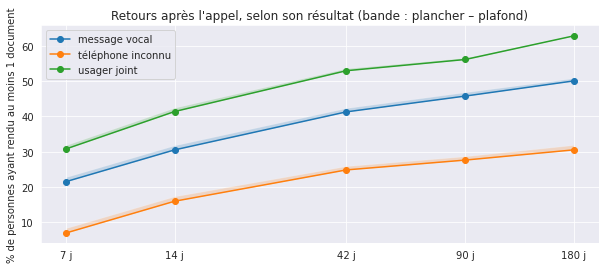

In [22]:
fig, ax = plt.subplots(figsize=(10, 4))
t = effet_appel[(effet_appel['indicateur'] == 'au moins 1 doc rendu') & (effet_appel['résultat appel'] != 'Total')]
for groupe, g in t.groupby('résultat appel'):
    x = [int(d.split()[0]) for d in g['délai']]
    ax.plot(x, g['plancher_%'], marker='o', label=groupe)
    ax.fill_between(x, g['plancher_%'], g['plafond_%'], alpha=0.2)
ax.set_xscale('log')
ax.set_xticks(DELAIS_APPEL)
ax.set_xticklabels([f'{j} j' for j in DELAIS_APPEL])
ax.set_ylabel('% de personnes ayant rendu au moins 1 document')
ax.set_title("Retours après l'appel, selon son résultat (bande : plancher – plafond)")
ax.legend()
plt.show()

# 5. Régularité des appels

Les appels sont-ils faits de façon régulière, et au bon moment ? On compare, mois par mois, le nombre d'appels notés dans le bloc `B_` au nombre de personnes (hors collectivités) qui franchissent 28 jours de retard.

Limites :
- le bloc ne garde que le **dernier** appel : une personne appelée en 2025 puis en 2026 n'apparaît qu'en 2026. Les volumes anciens sont donc **sous-estimés** ;
- « appelée ensuite » compte aussi un appel noté plus tard pour un autre dossier : la couverture peut être **surestimée** ;
- les derniers mois sont incomplets (des personnes peuvent encore être appelées).

In [23]:
DEBUT_REGULARITE = pd.Timestamp('2025-01-01')
fmt_appel = np.where(adh['B_address'].astype(str).str.strip().str.fullmatch(r'\d{2}/\d{2}/\d{4}'), 'JJ/MM/AAAA', 'AAAA-MM-JJ')
ap = adh.assign(format_date=fmt_appel)
ap = ap[(ap['date_appel'] >= DEBUT_REGULARITE) & (ap['date_appel'] <= fraicheur)][['borrowernumber', 'date_appel', 'format_date']]

jours_appel = ap.groupby('date_appel').size()
print(len(ap), "appels notés depuis", DEBUT_REGULARITE.date(), "sur", len(jours_appel), "jours différents")
print("appels par jour d'appel :", jours_appel.describe(percentiles=[.25, .5, .75, .9]).round(1).to_dict())
ecarts = jours_appel.index.to_series().diff().dt.days.dropna()
print("intervalle entre deux jours d'appels (j) :", ecarts.describe(percentiles=[.25, .5, .75, .9]).round(0).to_dict())
jours_fr = ['lundi', 'mardi', 'mercredi', 'jeudi', 'vendredi', 'samedi', 'dimanche']
ap['date_appel'].dt.dayofweek.map(dict(enumerate(jours_fr))).value_counts().reindex(jours_fr).fillna(0).astype(int).to_frame('appels').T

2095 appels notés depuis 2025-01-01 sur 133 jours différents
appels par jour d'appel : {'count': 133.0, 'mean': 15.8, 'std': 24.1, 'min': 1.0, '25%': 2.0, '50%': 7.0, '75%': 20.0, '90%': 37.6, 'max': 158.0}
intervalle entre deux jours d'appels (j) : {'count': 132.0, 'mean': 5.0, 'std': 6.0, 'min': 1.0, '25%': 1.0, '50%': 3.0, '75%': 6.0, '90%': 11.0, 'max': 31.0}


,lundi,mardi,mercredi,jeudi,vendredi,samedi,dimanche
appels,134,314,672,440,316,219,0


## Besoin et appels, mois par mois

Historique des prêts reconstitué comme en section 4 : emprunteur pris dans `statdb.stat_issues`, échéance et retour dans Koha (prêt toujours emprunté s'il figure dans `koha_prod.issues`). Les jointures sont faites en mémoire.

In [24]:
debut_prets = (DEBUT_REGULARITE - pd.DateOffset(months=7)).date()
st = pd.read_sql(f"""
SELECT borrowernumber, itemnumber, issuedate, date_due AS due_s, returndate AS ret_s, categorycode
FROM statdb.stat_issues WHERE issuedate >= '{debut_prets}'
""", db_conn)
cours = pd.read_sql("SELECT itemnumber, issuedate, date_due AS due_k FROM koha_prod.issues", db_conn)
cours['en_cours'] = True
anciens = pd.read_sql(f"""
SELECT itemnumber, issuedate, date_due AS due_o, returndate AS ret_o
FROM koha_prod.old_issues WHERE issuedate >= '{debut_prets}' AND itemnumber IS NOT NULL
""", db_conn)
pr = st.merge(cours, on=['itemnumber', 'issuedate'], how='left').merge(anciens, on=['itemnumber', 'issuedate'], how='left')
pr['en_cours'] = pr['en_cours'].fillna(False).astype(bool)
pr['echeance'] = pd.to_datetime(pr['due_k'].fillna(pr['due_o']).fillna(pr['due_s']), errors='coerce').dt.normalize()
pr['retour'] = pd.to_datetime(pr['ret_o'].fillna(pr['ret_s']), errors='coerce').dt.normalize().where(~pr['en_cours'])

# personnes (hors collectivités et comptes génériques) qui franchissent 28 j de retard dans le mois
b28 = pr[~pr['categorycode'].isin(COLLECTIVITES + ['CGEN'])].copy()
b28['jour_29'] = b28['echeance'] + pd.Timedelta(days=SEUIL_STOCK + 1)
b28 = b28[(b28['jour_29'] >= DEBUT_REGULARITE) & (b28['jour_29'] <= fraicheur)
          & (b28['en_cours'] | b28['retour'].isna() | (b28['retour'] >= b28['jour_29']))]
b28['mois'] = b28['jour_29'].dt.to_period('M')

entrees_28 = b28.sort_values('jour_29').drop_duplicates(['borrowernumber', 'mois'])
entrees_28 = entrees_28.merge(ap[['borrowernumber', 'date_appel']], on='borrowernumber', how='left')
entrees_28['appelee_ensuite'] = entrees_28['date_appel'] >= entrees_28['jour_29'] - pd.Timedelta(days=1)

regularite = pd.DataFrame({
    'franchissent 28 j': entrees_28.groupby('mois').size(),
    'appels notés': ap.groupby(ap['date_appel'].dt.to_period('M')).size(),
    "jours d'appels": ap.groupby(ap['date_appel'].dt.to_period('M'))['date_appel'].nunique(),
    'appelées ensuite_%': 100 * entrees_28.groupby('mois')['appelee_ensuite'].mean(),
}).fillna(0)
regularite.round(0).astype(int).T

,2025-01,2025-02,2025-03,2025-04,2025-05,2025-06,2025-07,2025-08,2025-09,2025-10,2025-11,2025-12,2026-01,2026-02,2026-03,2026-04,2026-05,2026-06,2026-07,2026-08,2026-09,2026-10
franchissent 28 j,511,319,342,420,372,394,364,299,245,230,296,357,362,291,369,398,372,234,244,200,158,82
appels notés,2,1,6,7,14,39,32,37,39,10,18,100,216,253,218,345,275,191,176,23,87,6
jours d'appels,2,1,3,3,4,5,7,11,8,4,4,10,12,8,10,11,7,7,8,3,4,1
appelées ensuite_%,29,31,35,31,33,32,30,29,41,31,36,50,69,76,61,51,39,52,58,36,22,0


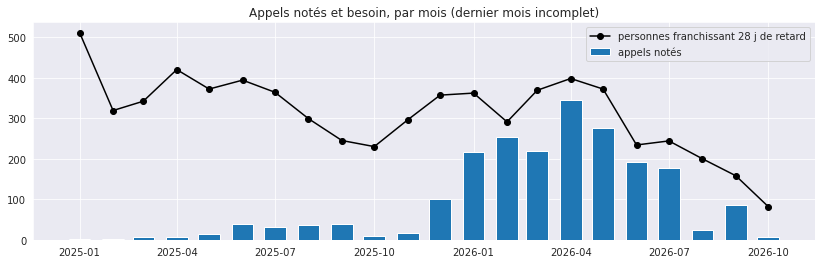

In [25]:
fig, ax = plt.subplots(figsize=(14, 4))
x = regularite.index.to_timestamp()
ax.bar(x, regularite['appels notés'], width=20, label='appels notés')
ax.plot(x, regularite['franchissent 28 j'], color='black', marker='o', label='personnes franchissant 28 j de retard')
ax.set_title('Appels notés et besoin, par mois (dernier mois incomplet)')
ax.legend()
plt.show()

## Délai entre l'échéance et l'appel

Retard de la personne au jour de l'appel : plus ancienne échéance encore en retard ce jour-là. Le circuit prévoit l'appel à partir de 28 jours.

In [26]:
h = pr.merge(ap[['borrowernumber', 'date_appel']], on='borrowernumber')
h = h[(h['issuedate'] < h['date_appel']) & (h['echeance'] < h['date_appel'])
      & (h['en_cours'] | h['retour'].isna() | (h['retour'] > h['date_appel']))]
ret_appel = h.groupby(['borrowernumber', 'date_appel'])['echeance'].min().reset_index()
ret_appel['retard'] = (ret_appel['date_appel'] - ret_appel['echeance']).dt.days
ret_appel['trimestre'] = ret_appel['date_appel'].dt.to_period('Q')
t = ret_appel.groupby('trimestre')['retard'].describe(percentiles=[.25, .5, .75])[['count', '25%', '50%', '75%']]
t['29-42 j_%'] = ret_appel.groupby('trimestre')['retard'].apply(lambda s: 100 * s.between(29, 42).mean())
t['> 90 j_%'] = ret_appel.groupby('trimestre')['retard'].apply(lambda s: 100 * (s > 90).mean())
t.round(0).T

trimestre,2025Q1,2025Q2,2025Q3,2025Q4,2026Q1,2026Q2,2026Q3,2026Q4
count,7.0,55.0,99.0,120.0,555.0,644.0,265.0,6.0
25%,66.0,35.0,30.0,35.0,32.0,35.0,33.0,52.0
50%,72.0,40.0,33.0,38.0,34.0,45.0,40.0,56.0
75%,76.0,44.0,37.0,41.0,39.0,446.0,46.0,57.0
29-42 j_%,0.0,69.0,85.0,74.0,84.0,44.0,54.0,0.0
> 90 j_%,14.0,0.0,3.0,0.0,4.0,37.0,2.0,0.0


## Dates d'appel suspectes

Beaucoup d'appels sont datés du 20 du mois, y compris un lundi ou un samedi : il s'agit probablement d'une date de saisie groupée ou conventionnelle plutôt que du jour réel de l'appel. À vérifier avec les personnes qui saisissent.

In [27]:
print("jours du mois les plus fréquents :", ap['date_appel'].dt.day.value_counts().head(6).to_dict())
le_20 = ap[ap['date_appel'].dt.day == 20]
pd.crosstab(le_20['date_appel'].dt.date.astype(str) + ' (' + le_20['date_appel'].dt.dayofweek.map(dict(enumerate(jours_fr))) + ')',
            le_20['format_date'], margins=True, margins_name='Total')

jours du mois les plus fréquents : {20: 455, 18: 167, 4: 151, 16: 109, 26: 95, 15: 88}


format_date,AAAA-MM-JJ,JJ/MM/AAAA,Total
date_appel,,,
2025-09-20 (samedi),2,0,2
2025-12-20 (samedi),1,0,1
2026-01-20 (mardi),2,18,20
2026-02-20 (vendredi),0,2,2
2026-03-20 (vendredi),14,49,63
2026-04-20 (lundi),0,134,134
2026-05-20 (mercredi),0,158,158
2026-06-20 (samedi),0,75,75
Total,19,436,455


# 6. Profil des personnes du stock (particuliers)

In [28]:
part = stock[stock['type'] == 'particulier'].copy()
age = (fraicheur - pd.to_datetime(part['dateofbirth'], errors='coerce')).dt.days / 365.25
part['tranche_age'] = pd.cut(age, [-1, 11, 17, 24, 39, 59, 74, 200], labels=['0-11', '12-17', '18-24', '25-39', '40-59', '60-74', '75+'])
part['carte_expiree'] = pd.to_datetime(part['dateexpiry'], errors='coerce') < fraicheur
part['a_emprunte_depuis'] = pd.to_datetime(part['dernier_pret'], errors='coerce') > part['plus_ancienne_echeance']
part['contact'] = np.select([part['tel'] & part['courriel'], part['tel'], part['courriel']],
                            ['téléphone + courriel', 'téléphone seul', 'courriel seul'], default='aucun')

for col in ['categorycode', 'branchcode', 'tranche_age', 'contact', 'carte_expiree', 'a_emprunte_depuis']:
    print(f"\n=== {col}")
    display(pd.crosstab(part[col], part['tranche'], margins=True, margins_name='Total'))


=== categorycode


tranche,29-42 j,43-90 j,91-180 j,181-365 j,1-2 ans,> 2 ans,Total
categorycode,,,,,,,
BIBL,52,65,120,189,354,1767,2547
CSLT,0,0,0,0,2,21,23
CSVT,2,2,0,2,1,15,22
MEDA,0,2,0,0,1,5,8
MEDB,1,0,0,0,1,14,16
MEDC,3,1,5,7,5,46,67
MEDP,2,1,3,1,1,3,11
Total,60,71,128,199,365,1871,2694



=== branchcode


tranche,29-42 j,43-90 j,91-180 j,181-365 j,1-2 ans,> 2 ans,Total
branchcode,,,,,,,
BUS,0,1,0,8,20,100,129
MED,60,70,128,191,345,1771,2565
Total,60,71,128,199,365,1871,2694



=== tranche_age


...

tranche,29-42 j,43-90 j,91-180 j,181-365 j,1-2 ans,> 2 ans,Total
contact,,,,,,,
aucun,1,0,2,3,9,239,254
courriel seul,1,2,2,22,11,51,89
téléphone + courriel,55,64,117,159,296,1119,1810
téléphone seul,3,5,7,15,49,462,541
Total,60,71,128,199,365,1871,2694



=== carte_expiree


tranche,29-42 j,43-90 j,91-180 j,181-365 j,1-2 ans,> 2 ans,Total
carte_expiree,,,,,,,
False,55,64,106,124,10,16,375
True,5,7,22,75,355,1855,2319
Total,60,71,128,199,365,1871,2694



=== a_emprunte_depuis


tranche,29-42 j,43-90 j,91-180 j,181-365 j,1-2 ans,> 2 ans,Total
a_emprunte_depuis,,,,,,,
False,59,71,124,193,348,1784,2579
True,1,0,4,6,17,87,115
Total,60,71,128,199,365,1871,2694


Les personnes qui ont **emprunté à nouveau depuis le début de leur retard** sont revenues à la médiathèque : elles peuvent être interceptées au guichet. On regarde leur part selon l'ancienneté du retard.

In [29]:
(100 * part.groupby('tranche')['a_emprunte_depuis'].mean()).round(1)

tranche
29-42 j      1.7
43-90 j      0.0
91-180 j     3.1
181-365 j    3.0
1-2 ans      4.7
> 2 ans      4.6
Name: a_emprunte_depuis, dtype: float64

# 7. Les documents du stock

In [30]:
docs = r.merge(stock[['borrowernumber', 'type', 'tranche']], on='borrowernumber')
docs = docs[docs['type'] == 'particulier']
print("statut de l'exemplaire (itemlost : 0 = disponible en théorie, 1 = non restitué, 2 = perdu) :")
display(pd.crosstab(docs['itemlost'].fillna(-1).astype(int), docs['tranche'], margins=True, margins_name='Total'))
print("documents dont le titre fait l'objet d'une réservation en attente :", int(docs['titre_reserve'].sum()))
display(docs.groupby('tranche')['titre_reserve'].sum())

statut de l'exemplaire (itemlost : 0 = disponible en théorie, 1 = non restitué, 2 = perdu) :


tranche,29-42 j,43-90 j,91-180 j,181-365 j,1-2 ans,> 2 ans,Total
itemlost,,,,,,,
0,204,53,1,0,4,89,351
1,2,146,308,430,828,4872,6586
2,0,0,0,0,0,1,1
Total,206,199,309,430,832,4962,6938


documents dont le titre fait l'objet d'une réservation en attente : 357


tranche
29-42 j       28
43-90 j       19
91-180 j      32
181-365 j     41
1-2 ans       65
> 2 ans      172
Name: titre_reserve, dtype: int64

In [31]:
t = docs.groupby('itype').agg(docs=('itemnumber', 'size'), valeur_bas=('prix_bas', 'sum'), prix_median=('prix', 'median'))
t.sort_values('docs', ascending=False).head(15).round(1)

,docs,valeur_bas,prix_median
itype,,,
PRETLIV,6357,62274.0,10.9
PRETPER,259,127.0,18.0
PRETDVD,192,4458.3,35.8
PRETSON,84,1284.5,16.6
PRETLS,33,514.7,19.4
PRETPAR,12,213.8,20.7
PRETCAR,1,5.3,5.3


# 8. Entrées et sorties du stock (24 derniers mois)

Au niveau des prêts, toutes catégories :
- **entrée** : prêt dont le retard atteint 29 jours dans le mois (et non rendu à cette date) ;
- **sortie** : retour dans le mois d'un prêt qui avait plus de 28 jours de retard.

La différence explique l'évolution du stock. Les prêts jamais rendus ne sortent pas.

In [32]:
flux = pd.read_sql(f"""
SELECT date_due, returndate FROM (
    SELECT date_due, NULL AS returndate FROM koha_prod.issues
    UNION ALL
    SELECT date_due, returndate FROM koha_prod.old_issues WHERE date_due >= DATE_SUB('{fraicheur.date()}', INTERVAL 30 MONTH)
) t
WHERE DATE_ADD(date_due, INTERVAL {SEUIL_STOCK} DAY) < '{fraicheur.date()}'
  AND (returndate IS NULL OR returndate > DATE_ADD(date_due, INTERVAL {SEUIL_STOCK} DAY))
""", db_conn)
flux['entree'] = (pd.to_datetime(flux['date_due'], errors='coerce').dt.normalize() + pd.Timedelta(days=SEUIL_STOCK + 1)).dt.to_period('M')
flux['sortie'] = pd.to_datetime(flux['returndate'], errors='coerce').dt.to_period('M')
debut = (fraicheur - pd.DateOffset(months=24)).to_period('M')
mois = pd.period_range(debut, fraicheur.to_period('M'), freq='M')
es = pd.DataFrame({'entrées': flux.groupby('entree').size(), 'sorties': flux.groupby('sortie').size()}).reindex(mois).fillna(0).astype(int)
es['solde'] = es['entrées'] - es['sorties']
es.T

,2024-10,2024-11,2024-12,2025-01,2025-02,2025-03,2025-04,2025-05,2025-06,2025-07,2025-08,2025-09,2025-10,2025-11,2025-12,2026-01,2026-02,2026-03,2026-04,2026-05,2026-06,2026-07,2026-08,2026-09,2026-10
entrées,1042,810,1075,1698,688,1142,1105,1210,1219,1126,1318,1125,778,987,1136,1187,923,1102,990,782,637,1449,756,566,328
sorties,1243,775,868,1359,1014,1024,1142,976,1186,887,877,1478,859,891,1038,1106,937,1001,955,579,713,959,536,850,253
solde,-201,35,207,339,-326,118,-37,234,33,239,441,-353,-81,96,98,81,-14,101,35,203,-76,490,220,-284,75


Le dernier mois est incomplet (données arrêtées au 2026-10-14 ).


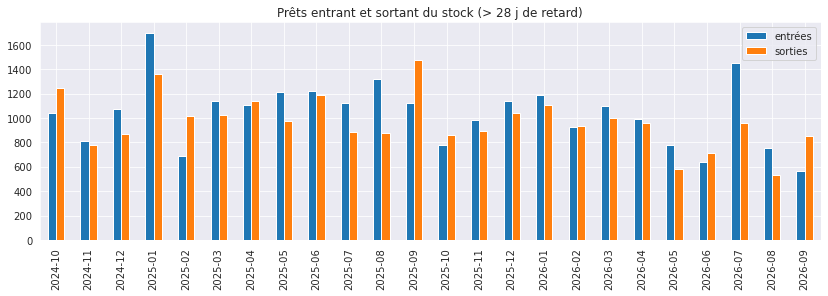

In [33]:
print("Le dernier mois est incomplet (données arrêtées au", fraicheur.date(), ").")
ax = es[['entrées', 'sorties']].iloc[:-1].plot.bar(figsize=(14, 4), title='Prêts entrant et sortant du stock (> 28 j de retard)')
ax.set_xlabel('')
plt.show()

# 9. Anomalies à traiter

In [34]:
bloc = renseigne(adh['B_address']) | renseigne(adh['B_address2']) | renseigne(adh['B_country']) | renseigne(adh['B_state'])
sans_retard = bloc & ~adh['borrowernumber'].isin(stock['borrowernumber'])
anomalies = {
    "bloc B_ rempli, aucun document en retard > 28 j": int(sans_retard.sum()),
    "  dont aucun prêt en cours": int((sans_retard & ~adh['borrowernumber'].isin(prets['borrowernumber'])).sum()),
    "dates B_ au format JJ/MM/AAAA (appel)": int(adh['B_address'].astype(str).str.fullmatch(r'\d{2}/\d{2}/\d{4}').sum()),
    "dates B_ illisibles (appel / tiers / titre)": int(adh[['date_appel_illisible', 'date_tiers_illisible', 'date_titre_illisible']].any(axis=1).sum()),
    "résultat d'appel hors valeurs admises": int((renseigne(adh['B_address2']) & adh['resultat_appel'].isna()).sum()),
    "titre 0 avec montant noté ≥ 15 €": int(((adh['titre'] == '0 (< 15 €)') & (adh['montant_note'] >= SEUIL_TITRE_EUR)).sum()),
    "titre numéroté avec montant noté < 15 €": int(((adh['titre'] == 'numéro') & (adh['montant_note'] < SEUIL_TITRE_EUR)).sum()),
    "particuliers du stock, bloc B_ d'un dossier antérieur": int(stock.loc[stock['type'] == 'particulier', 'bloc_dossier_anterieur'].sum()),
}
pd.Series(anomalies, name='fiches').to_frame()

,fiches
"bloc B_ rempli, aucun document en retard > 28 j",1401
dont aucun prêt en cours,1013
dates B_ au format JJ/MM/AAAA (appel),1173
dates B_ illisibles (appel / tiers / titre),30
résultat d'appel hors valeurs admises,22
titre 0 avec montant noté ≥ 15 €,31
titre numéroté avec montant noté < 15 €,41
"particuliers du stock, bloc B_ d'un dossier antérieur",131


# Limites
- Photographie à la date de fraîcheur ; la base de travail est une copie qui n'est pas à jour au jour près.
- Le bloc `B_` ne garde qu'une information par étape : l'historique des dossiers successifs d'une même personne est perdu, et la section 4 ne voit que le dernier appel.
- Le sens de `B_state = 0` (montant < 15 €) est déduit statistiquement, pas documenté.
- La valeur du stock repose sur le prix de remplacement Koha, qui peut différer du montant facturé.